# 2. Unsupervised Learning

Objective Function of K-Means

The K-Means algorithm partitions $N$ data points $(x_1, \ldots, x_N)$ into $K$ clusters by minimizing the **within-cluster sum of squared distances (WCSS)**:

$$
L(\mathcal{Z}, A) = \sum_{i=1}^{N} \| x_i - z_{A(x_i)} \|^2
$$

Here, $z_{A(x_i)}$ is the centroid of the cluster assigned to $x_i$, and $\mathcal{Z}$ denotes the set of centroids.

---

Optimization Process

K-Means follows an iterative Expectation-Maximization-like procedure:

1. Initialization
Choose $K$ initial centroids (randomly or using K-Means++).

2. Project Step (E-Step)
Assign each point to the nearest centroid:

$$
A(x_i) = \arg\min_j \| x_i - z_j \|
$$

3. Update Step (M-Step)
Update each centroid as the mean of points assigned to it:

$$
z_j = \frac{1}{|\mathcal{C}_j|} \sum_{x_i \in \mathcal{C}_j} x_i
$$

4. Iterate
Repeat until projects or centroids stop changing.

---

Time and Space Complexity

Time Complexity
For $I$ iterations, $K$ clusters, $N$ points, and $d$-dimensional features:

$$
O(I \cdot K \cdot N \cdot d)
$$

Space Complexity
Must store:

- Dataset: $N \times d$
- Projects: $N$
- Centroids: $K \times d$

---

Limitations

- Assumes clusters are **spherical**, equally sized, and non-overlapping.
- Sensitive to **initialization**.
- Performs poorly for:
  - elongated clusters  
  - unequal cluster density  
  - irregular shapes  
- Sensitive to **outliers**.


In [ ]:
import numpy as np

class KMeans:
    def __init__(self, n_clusters=3, max_iter=100, tol=1e-4, random_state=None):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state

    def fit(self, X):
        np.random.seed(self.random_state)
        n_samples, n_features = X.shape

        # 1. Initialize centroids by randomly choosing k points from data
        random_indices = np.random.choice(n_samples, self.n_clusters, replace=False)
        self.centroids = X[random_indices, :]

        for iteration in range(self.max_iter):
            # 2. Project step - assign each point to the closest centroid
            distances = np.linalg.norm(X[:, np.newaxis] - self.centroids, axis=2)  # Shape: (n_samples, n_clusters)
            labels = np.argmin(distances, axis=1)

            # 3. Update step - recalculate centroids as mean of assigned points
            new_centroids = np.copy(self.centroids)
            for k in range(self.n_clusters):
                members = X[labels == k]
                if len(members) > 0:
                    new_centroids[k] = members.mean(axis=0)
                else:
                    # If no points assigned, keep centroid unchanged
                    new_centroids[k] = self.centroids[k]

            # 4. Check for convergence (movement of centroids below tolerance)
            centroid_shifts = np.linalg.norm(new_centroids - self.centroids, axis=1)
            self.centroids = new_centroids
            if np.all(centroid_shifts <= self.tol):
                break

        self.labels_ = labels  # Save the final labels

    def predict(self, X):
        distances = np.linalg.norm(X[:, np.newaxis] - self.centroids, axis=2)
        return np.argmin(distances, axis=1)

    def wcss(self, X):
        total_wcss = 0.0
        labels = self.predict(X)
        for k in range(self.n_clusters):
            members = X[labels == k]
            if len(members) > 0:
                diffs = members - self.centroids[k]
                sq_dists = np.sum(np.square(diffs))
                total_wcss += sq_dists
        return total_wcss



Dataset A loaded from E:\ACADEMICS\Semester-3\Courses\Foundations of Machine Learning\PA\PA4\data\data\dataset_A.csv, shape: (1250, 2)


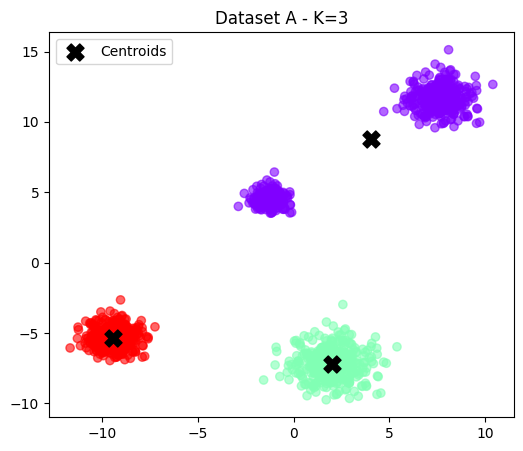

Dataset A - WCSS: 17265.0609

Dataset B loaded from E:\ACADEMICS\Semester-3\Courses\Foundations of Machine Learning\PA\PA4\data\data\dataset_B.csv, shape: (950, 2)


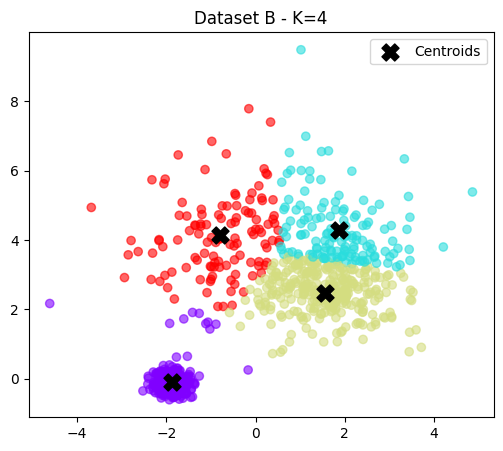

Dataset B - WCSS: 826.4289

Dataset C loaded from E:\ACADEMICS\Semester-3\Courses\Foundations of Machine Learning\PA\PA4\data\data\dataset_C.csv, shape: (900, 2)


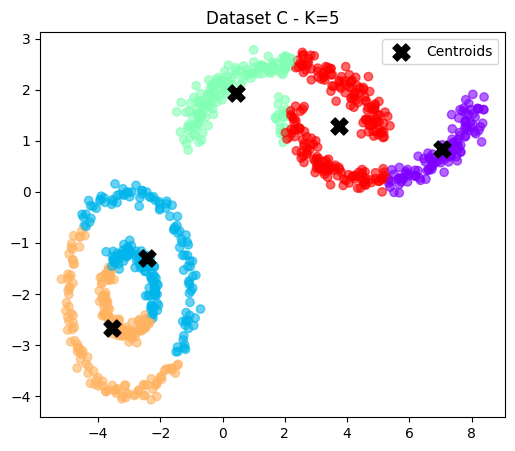

Dataset C - WCSS: 1297.2556


In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Assuming 'KMeansScratch' class is already defined as in previous messages

# Paths to your dataset CSV files
dataset_paths = [
    "E:\\ACADEMICS\\Semester-3\\Courses\\Foundations of Machine Learning\\PA\\PA4\\data\\data\\dataset_A.csv",
    "E:\\ACADEMICS\\Semester-3\\Courses\\Foundations of Machine Learning\\PA\\PA4\\data\\data\\dataset_B.csv",
    "E:\\ACADEMICS\\Semester-3\\Courses\\Foundations of Machine Learning\\PA\\PA4\\data\\data\\dataset_C.csv"
]

# Preset appropriate K values for each dataset (adjust as per your PDF instructions)
K_values = [3, 4, 5]  # Example values, replace with exact K from your project

for i, path in enumerate(dataset_paths):
    # Load dataset as numpy array
    df = pd.read_csv(path)
    X = df.values  
    
    print(f"\nDataset {chr(65 + i)} loaded from {path}, shape: {X.shape}")
    
    # Initialize and fit K-Means
    kmeans = KMeans(n_clusters=K_values[i], max_iter=100, tol=1e-4, random_state=42)
    kmeans.fit(X)
    
    # Get labels and centroids
    labels = kmeans.labels_
    centroids = kmeans.centroids
    
    # Visualization for 2D datasets
    if X.shape[1] == 2:
        plt.figure(figsize=(6, 5))
        plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='rainbow', alpha=0.6)
        plt.scatter(centroids[:, 0], centroids[:, 1], marker='X', c='black', s=150, label='Centroids')
        plt.title(f"Dataset {chr(65 + i)} - K={K_values[i]}")
        plt.legend()
        plt.show()
    else:
        print(f"Dataset {chr(65 + i)} has {X.shape[1]} features; skipping 2D plot.")
    
    # Calculate and print Within-Cluster Sum of Squares (WCSS)
    wcss = kmeans.wcss(X)
    print(f"Dataset {chr(65 + i)} - WCSS: {wcss:.4f}")


The complete data log-likelihood for observed data  
$X = \{x_1, x_2, \ldots, x_N\}$,  
latent variables $Z_i$,  
and parameters $\theta = \{\pi_k, \mu_k, \Sigma_k\}_{k=1}^K$ is

$$
\log p(X, Z \mid \theta)
=
\sum_{i=1}^N
\sum_{k=1}^K
\mathbf{1}_{\{Z_i = k\}}
\left[
\log \pi_k
+
\log \mathcal{N}(x_i \mid \mu_k, \Sigma_k)
\right]
$$

The E-step of the EM algorithm computes responsibilities:

$$
\gamma_{ik}
=
\frac{
\pi_k^{(t)}
\,\mathcal{N}(x_i \mid \mu_k^{(t)}, \Sigma_k^{(t)})
}{
\sum_{j=1}^K
\pi_j^{(t)}
\,\mathcal{N}(x_i \mid \mu_j^{(t)}, \Sigma_j^{(t)})
}
$$

The M-step updates the parameters.

Mixing weights:

$$
\pi_k^{(t+1)}
=
\frac{1}{N}
\sum_{i=1}^N
\gamma_{ik}
$$

Means:

$$
\mu_k^{(t+1)}
=
\frac{
\sum_{i=1}^N
\gamma_{ik} x_i
}{
\sum_{i=1}^N 
\gamma_{ik}
}
$$

Covariance matrices:

$$
\Sigma_k^{(t+1)}
=
\frac{
\sum_{i=1}^N
\gamma_{ik}
(x_i - \mu_k^{(t+1)})
(x_i - \mu_k^{(t+1)})^T
}{
\sum_{i=1}^N
\gamma_{ik}
}
$$

Soft projects in GMM give each point probabilities  
$(\gamma_{i1}, \gamma_{i2}, \ldots, \gamma_{iK})$,  
allowing overlap and uncertainty, while hard projects in K-means give each point exactly one cluster using a one-hot label.


In [36]:
import numpy as np
import pandas as pd
from scipy.stats import multivariate_normal
import matplotlib.pyplot as plt

class GMMFromScratch:
    def __init__(self, n_components=2, max_iter=100, tol=1e-3, random_state=42):
        self.K = n_components
        self.max_iter = max_iter
        self.tol = tol
        np.random.seed(random_state)

    def _init_params(self, X):
        N, D = X.shape
        # Randomly assign labels
        labels = np.random.choice(self.K, N)
        self.weights_ = np.ones(self.K) / self.K
        self.means_ = np.array([X[labels == k].mean(axis=0) for k in range(self.K)])
        self.covariances_ = np.array([np.cov(X[labels == k].T) + np.eye(D)*1e-6 for k in range(self.K)])

    def _e_step(self, X):
        N = X.shape[0]
        resp = np.zeros((N, self.K))
        for k in range(self.K):
            rv = multivariate_normal(mean=self.means_[k], cov=self.covariances_[k], allow_singular=True)
            resp[:, k] = self.weights_[k] * rv.pdf(X)
        # Normalize
        resp = resp / resp.sum(axis=1, keepdims=True)
        return resp

    def _m_step(self, X, resp):
        N, D = X.shape
        Nk = resp.sum(axis=0)
        self.weights_ = Nk / N
        self.means_ = (resp.T @ X) / Nk[:, np.newaxis]
        self.covariances_ = np.zeros((self.K, D, D))
        for k in range(self.K):
            diff = X - self.means_[k]
            self.covariances_[k] = (resp[:, k][:, np.newaxis] * diff).T @ diff / Nk[k]
            self.covariances_[k] += np.eye(D) * 1e-6  # Regularization

    def _compute_log_likelihood(self, X):
        N = X.shape[0]
        total = np.zeros((N, self.K))
        for k in range(self.K):
            rv = multivariate_normal(mean=self.means_[k], cov=self.covariances_[k], allow_singular=True)
            total[:, k] = self.weights_[k] * rv.pdf(X)
        return np.sum(np.log(np.sum(total, axis=1) + 1e-10))

    def fit(self, X):
        self._init_params(X)
        log_likelihoods = []
        for i in range(self.max_iter):
            resp = self._e_step(X)
            self._m_step(X, resp)
            ll = self._compute_log_likelihood(X)
            log_likelihoods.append(ll)
            # Check for convergence
            if i > 0 and abs(log_likelihoods[-1] - log_likelihoods[-2]) < self.tol:
                break
        self.resp_ = resp
        self.log_likelihoods_ = log_likelihoods

    def predict(self, X):
        resp = self._e_step(X)
        return np.argmax(resp, axis=1)

    def predict_proba(self, X):
        return self._e_step(X)


K_values = [3, 4, 5] # Set appropriate K for each

gmm_models = []
for i, path in enumerate(dataset_paths):
    df = pd.read_csv(path)
    X = df.values
    gmm = GMMFromScratch(n_components=K_values[i], max_iter=100, tol=1e-3)
    gmm.fit(X)
    gmm_models.append((gmm, X))
    print(f"Dataset {chr(65+i)}: fitted GMM with {K_values[i]} components")


Dataset A: fitted GMM with 3 components
Dataset B: fitted GMM with 4 components
Dataset C: fitted GMM with 5 components


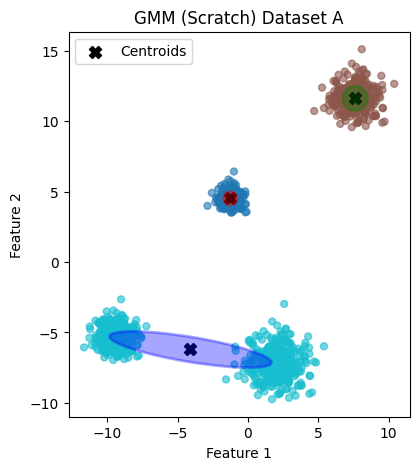

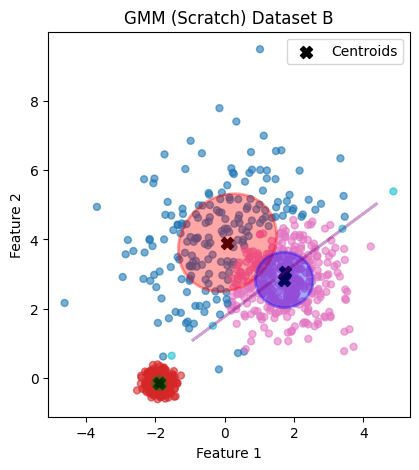

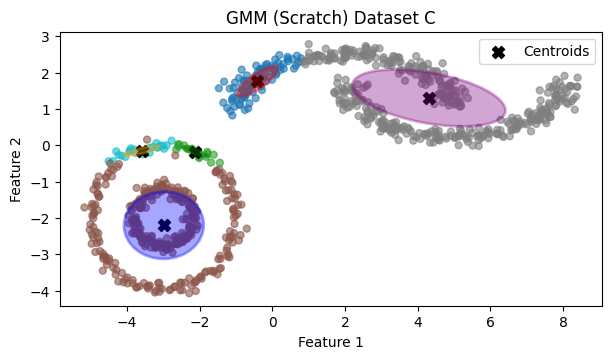

In [37]:
from matplotlib.patches import Ellipse

def plot_gmm_contours(gmm, X, ax, title):
    labels = gmm.predict(X)
    ax.scatter(X[:, 0], X[:, 1], c=labels, cmap='tab10', alpha=0.6, s=25)
    ax.scatter(gmm.means_[:, 0], gmm.means_[:, 1], c='black', marker='X', s=75, label='Centroids')
    # Use a list of distinct colors for each component
    colors = ['red', 'green', 'blue', 'purple', 'orange', 'cyan']
    for k in range(gmm.K):
        mean = gmm.means_[k]
        cov = gmm.covariances_[k]
        v, w = np.linalg.eigh(cov)
        angle = np.degrees(np.arctan2(w[0,1], w[0,0]))
        width, height = 2 * np.sqrt(v)
        ell = Ellipse(xy=mean, width=width, height=height, angle=angle,
                      edgecolor=colors[k % len(colors)], facecolor=colors[k % len(colors)],
                      alpha=0.35, linewidth=2)
        ax.add_patch(ell)
    ax.set_title(title)
    ax.set_aspect('equal')
    ax.legend()

for i, (gmm, X) in enumerate(gmm_models):
    fig, ax = plt.subplots(figsize=(7, 5))
    plot_gmm_contours(gmm, X, ax, f"GMM (Scratch) Dataset {chr(65+i)}")
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.show()

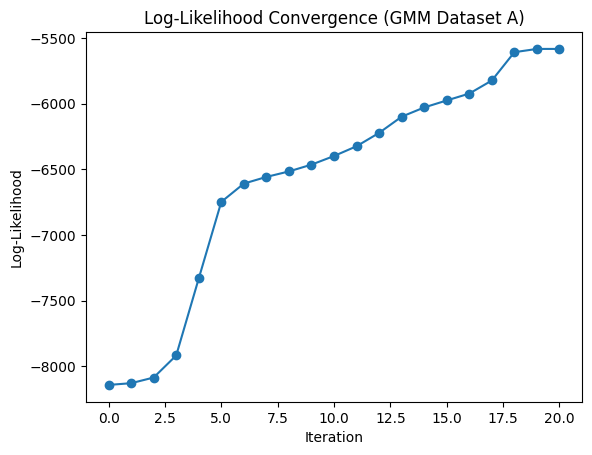

Final log-likelihood (A): -5582.97, EM rounds: 21


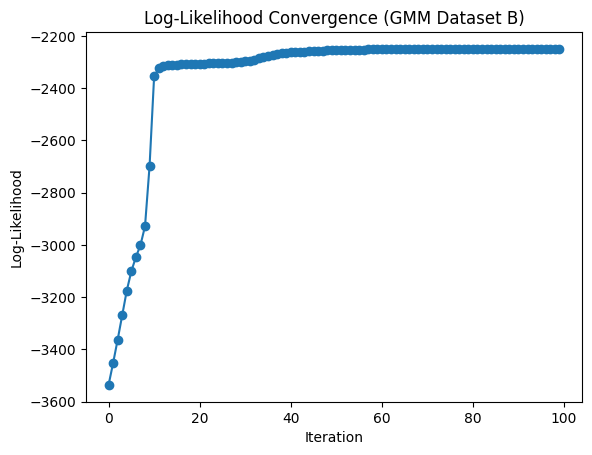

Final log-likelihood (B): -2249.92, EM rounds: 100


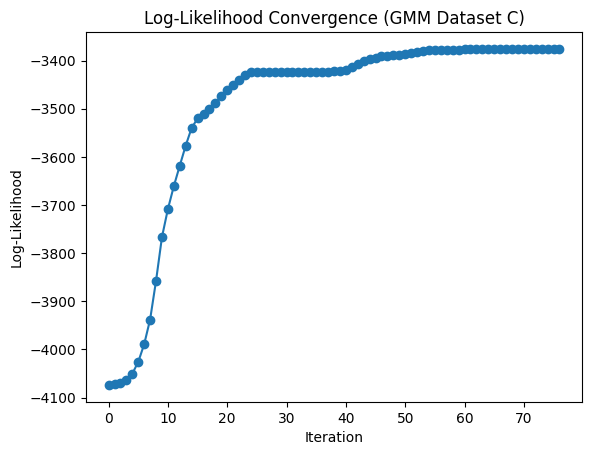

Final log-likelihood (C): -3375.84, EM rounds: 77


In [38]:
for i, (gmm, X) in enumerate(gmm_models):
    plt.plot(gmm.log_likelihoods_, marker='o')
    plt.title(f"Log-Likelihood Convergence (GMM Dataset {chr(65+i)})")
    plt.xlabel("Iteration")
    plt.ylabel("Log-Likelihood")
    plt.show()
    print(f"Final log-likelihood ({chr(65+i)}): {gmm.log_likelihoods_[-1]:.2f}, EM rounds: {len(gmm.log_likelihoods_)}")


**Experimental Analysis of GMM (from Scratch)**

1. GMM (EM algorithm) was implemented and fit to each dataset, learning probabilistic cluster projects and model parameters.
2. Cluster projects and probability contours visualize the flexibility of GMM in modeling elliptical and overlapping clusters.
3. The log-likelihood increases monotonically, confirming EM convergence and model improvement during iterations.
4. Comparing K-Means and GMM reveals that GMM is more adaptive to cluster shapes and overlaps, while K-Means tends to prefer spherical, equal-sized clusters.


# 1. Dimensionality Reduction

In [6]:
import numpy as np
import os
from imageio import imread

# Path to training data
train_dir = "E:\\ACADEMICS\\Semester-3\\Courses\\Foundations of Machine Learning\\PA\\PA4\\face_data\\face_data\\train"

image_files = [f for f in os.listdir(train_dir) if f.endswith('.png') or f.endswith('.jpg')]

images = []
for fname in sorted(image_files):  # Sorting for consistency
    img = imread(os.path.join(train_dir, fname))
    images.append(img)

print(f"Loaded {len(images)} images.")


C:\Users\pnspo\AppData\Local\Temp\ipykernel_20112\1176338663.py:12: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  img = imread(os.path.join(train_dir, fname))


Loaded 280 images.


In [7]:
# Assume all images are the same shape
h, w = images[0].shape
vectors = []
for img in images:
    vec = img.reshape(-1, order='F')  # Stack columns
    vectors.append(vec)

X = np.column_stack(vectors)
print(f"Data matrix X shape: {X.shape}")  # (h*w, N)


Data matrix X shape: (10304, 280)


In [8]:
# Compute the mean face vector

# Calculate the mean across all images for each pixel position
mean_face = np.mean(X, axis=1)  # Shape: (h*w,)

print(f"Mean face vector shape: {mean_face.shape}")


Mean face vector shape: (10304,)


In [9]:
# Mean center all image vectors in X

# Subtract the mean face from each image vector (broadcasting)
X_centered = X - mean_face[:, np.newaxis]

print(f"Mean-centered data matrix shape: {X_centered.shape}")


Mean-centered data matrix shape: (10304, 280)


In [12]:
# Compute the covariance matrix of the mean-centered data

# Sample covariance matrix for PCA
C = (1 / X_centered.shape[1]) * np.dot(X_centered, X_centered.T)

print(f"Covariance matrix shape: {C.shape}")


Covariance matrix shape: (10304, 10304)


**Eigen Decomposition for Principal Components**

This step computes the eigenvalues and eigenvectors of the covariance matrix. The eigenvalues and eigenvectors are then sorted in descending order of eigenvalues. The sorted eigenvectors represent the principal directions (principal components) corresponding to the largest variations in the data (for PCA).


In [13]:
# Compute and sort eigenvalues/eigenvectors of covariance matrix

# Eigen decomposition (use eigh since C is symmetric)
eigvals, eigvecs = np.linalg.eigh(C)

# Sort eigenvalues and eigenvectors in descending order
idx = np.argsort(eigvals)[::-1]
eigvals_sorted = eigvals[idx]
eigvecs_sorted = eigvecs[:, idx]

print("Sorted eigenvalues shape:", eigvals_sorted.shape)
print("Sorted eigenvectors shape:", eigvecs_sorted.shape)


Sorted eigenvalues shape: (10304,)
Sorted eigenvectors shape: (10304, 10304)


**Interpreting Eigenvalues and Eigenvectors**

The eigenvalues indicate the amount of variance captured by each principal component, while the corresponding eigenvectors represent the directions of maximum variance in the mean-centered data. Sorting these in descending order allows us to identify which principal components carry the most information, helping in dimensionality reduction and visualization of the most significant facial features.


**Selection of Principal Components**

By examining the sorted eigenvalues, we can choose the top \(k\) principal components that explain the majority of the variance in the dataset. Selecting components based on the largest eigenvalues ensures that most of the important information in the face images is preserved while reducing dimensionality for efficient processing and analysis.


**Projection and Reconstruction in PCA Subspace**

In this step, a given face image is projected onto the subspace formed by the top \(k\) principal components, resulting in a lower-dimensional feature vector. Then, the image is reconstructed by mapping the feature vector back to the original space. This demonstrates the dimensionality reduction and reconstruction processes using PCA.


In [14]:
# Choose k (number of principal components)
k = 50  # Example, we can change this value as needed

# Uk: matrix of the top-k eigenvectors
Uk = eigvecs_sorted[:, :k]  # Shape: (h*w, k)

# Assume test_image_vector is a vectorized, mean-centered test face
# For demonstration, use the first training image as a test
test_image_vector = X_centered[:, 0]

# Projection: get the lower-dimensional feature vector (PCA coefficients)
feature_vector = Uk.T @ test_image_vector  # Shape: (k,)

# Reconstruction: map feature vector back to original space
reconstructed = Uk @ feature_vector + mean_face  # Add the mean face back

print("Feature vector shape:", feature_vector.shape)
print("Reconstructed image shape:", reconstructed.shape)


Feature vector shape: (50,)
Reconstructed image shape: (10304,)


**Visual Comparison of Original and Reconstructed Image**

To evaluate the effectiveness of PCA reconstruction, this step visualizes the original face image and its reconstruction side by side. By comparing these images, we can assess how well the lower-dimensional PCA subspace preserves the critical features of the original face.


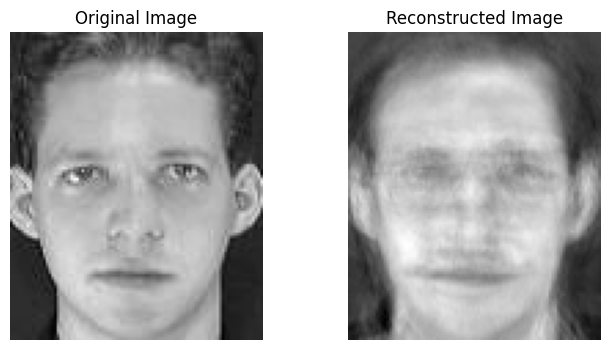

In [15]:
import matplotlib.pyplot as plt

# Reshape images back to 2D
original_img = test_image_vector + mean_face
original_img_2d = original_img.reshape(h, w, order='F')
reconstructed_2d = reconstructed.reshape(h, w, order='F')

# Plot original and reconstructed images
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(original_img_2d, cmap='gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title("Reconstructed Image")
plt.imshow(reconstructed_2d, cmap='gray')
plt.axis('off')
plt.show()


**Reconstruction Error Calculation**

In this step, the reconstruction error is quantified using the Mean Squared Error (MSE) between the original and reconstructed images. This error metric provides an objective measure of how much information is lost during dimensionality reduction and reconstruction with PCA.


In [16]:
# Compute Mean Squared Error between original and reconstructed images
mse = np.mean((original_img - reconstructed)**2)

print(f"Reconstruction Mean Squared Error: {mse:.4f}")


Reconstruction Mean Squared Error: 284.1827


**Reconstruction Error on Test Set**

In this step, we evaluate how the reconstruction error varies with the number of principal components by averaging the Mean Squared Error (MSE) across all test images. This provides insight into the generalization capability of PCA on unseen data.


C:\Users\pnspo\AppData\Local\Temp\ipykernel_20112\1870103639.py:7: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  img = imread(os.path.join(test_dir, fname))


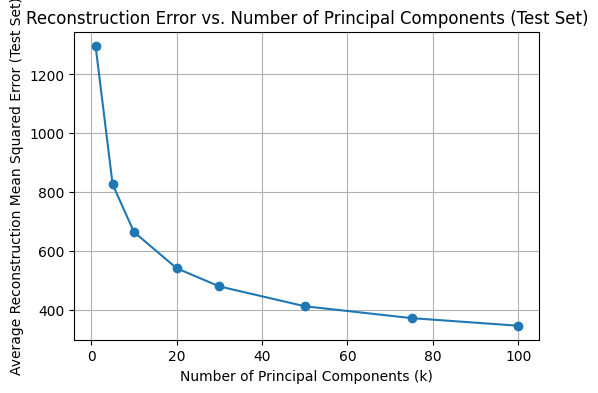

In [ ]:
# Prepare test data,read and vectorize test images
test_dir = "E:\\ACADEMICS\\Semester-3\\Courses\\Foundations of Machine Learning\\PA\\PA4\\face_data\\face_data\\test"
test_files = [f for f in os.listdir(test_dir) if f.endswith('.png') or f.endswith('.jpg')]

test_images = []
for fname in sorted(test_files):
    img = imread(os.path.join(test_dir, fname))
    vec = img.reshape(-1, order='F')
    test_images.append(vec)

test_X = np.column_stack(test_images)  # Each column is a vectorized test image

# Range of k values to evaluate
k_values = [1, 5, 10, 20, 30, 50, 75, 100]
mean_errors = []

for k in k_values:
    Uk = eigvecs_sorted[:, :k]
    errors = []
    for i in range(test_X.shape[1]):
        test_face = test_X[:, i]
        test_face_centered = test_face - mean_face  # Center using training mean
        feat_vec = Uk.T @ test_face_centered
        reconstructed = Uk @ feat_vec + mean_face
        mse = np.mean((test_face - reconstructed) ** 2)
        errors.append(mse)
    mean_errors.append(np.mean(errors))

# Plotting the result
plt.figure(figsize=(6, 4))
plt.plot(k_values, mean_errors, marker='o')
plt.xlabel("Number of Principal Components (k)")
plt.ylabel("Average Reconstruction Mean Squared Error (Test Set)")
plt.title("Reconstruction Error vs. Number of Principal Components (Test Set)")
plt.grid()
plt.show()


**Visual Comparison Across Different Numbers of Principal Components**

This section visualizes how the reconstructed appearance of test faces changes as the number of principal components \(k\) increases. By plotting both the original and reconstructed images for several \(k\) values, we can directly observe how the quality of reconstruction improves with more principal components.


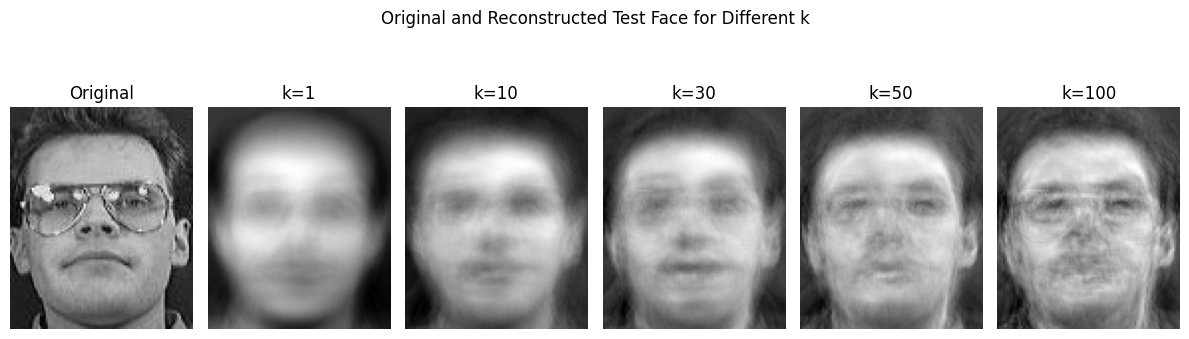

In [23]:
# Choose an index for a test image to visualize
img_idx = 10  # we can change this to view other images

# Choose k values to visualize
k_values_vis = [1, 10, 30, 50, 100]

# Original test face image
test_face = test_X[:, img_idx]
orig_2d = test_face.reshape(h, w, order='F')

plt.figure(figsize=(2 * (len(k_values_vis) + 1), 4))

# Show original image
plt.subplot(1, len(k_values_vis) + 1, 1)
plt.imshow(orig_2d, cmap='gray')
plt.title("Original")
plt.axis('off')

# Show reconstructions for different k
for j, k in enumerate(k_values_vis):
    Uk = eigvecs_sorted[:, :k]
    test_face_centered = test_face - mean_face
    feat_vec = Uk.T @ test_face_centered
    reconstructed = Uk @ feat_vec + mean_face
    reco_2d = reconstructed.reshape(h, w, order='F')
    
    plt.subplot(1, len(k_values_vis) + 1, j + 2)
    plt.imshow(reco_2d, cmap='gray')
    plt.title(f"k={k}")
    plt.axis('off')

plt.suptitle("Original and Reconstructed Test Face for Different k")
plt.tight_layout()
plt.show()


**Conclusions and Inferences: Compression vs. Reconstruction Quality**

Increasing the number of principal components \(k\) improves the quality of reconstructed face images, as more variance and features from the original data are retained. However, using a smaller \(k\) leads to greater dimensionality reduction and higher compression, at the expense of losing fine details and resulting in blurrier reconstructions. The optimal trade-off depends on the desired balance between retaining important facial features and minimizing the storage or computational costs. In practice, moderate values of \(k\) allow strong compression with only a small loss in visual quality, but extremely low \(k\) values can significantly degrade reconstruction fidelity.
